# Stage 4 — Macro-F1 Evaluation (no sklearn)

Loads the trained OvR model from Stage 3 and evaluates it on validation and test sets using a
from-scratch confusion matrix + per-class precision/recall/F1 + macro-F1 — no
`sklearn.metrics` anywhere.

**Why macro-F1 and not accuracy:** macro-F1 averages the F1 score **per language, unweighted**,
so a model that nails a few "easy" languages but quietly fails on one or two confusable ones
can't hide behind a good overall accuracy number — every one of the 23 languages counts equally
toward the final score. Since our test set is exactly balanced (100 sentences/language), macro-F1
and accuracy will be close here, but macro-F1 is still the methodologically correct choice and is
what actually surfaces per-language weaknesses.


In [1]:
import os
import json

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

DATA_DIR = "../data"

X_val = sp.load_npz(os.path.join(DATA_DIR, "X_val.npz")).tocsr()
X_test = sp.load_npz(os.path.join(DATA_DIR, "X_test.npz")).tocsr()
y_val = pd.read_csv(os.path.join(DATA_DIR, "y_val.csv"))["label"].values
y_test = pd.read_csv(os.path.join(DATA_DIR, "y_test.csv"))["label"].values

W = np.load(os.path.join(DATA_DIR, "model_W.npy"))
b = np.load(os.path.join(DATA_DIR, "model_b.npy"))
with open(os.path.join(DATA_DIR, "languages.json"), encoding="utf-8") as f:
    LANGUAGES = json.load(f)

print(f"W={W.shape}  b={b.shape}  languages={len(LANGUAGES)}")


W=(214895, 23)  b=(23,)  languages=23


In [2]:
def sigmoid(z):
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


def predict(X, W, b, languages):
    P = sigmoid(X.dot(W) + b)
    return np.array(languages)[P.argmax(axis=1)]


pred_val = predict(X_val, W, b, LANGUAGES)
pred_test = predict(X_test, W, b, LANGUAGES)
print("predicted", len(pred_val), "val labels and", len(pred_test), "test labels")


predicted 2300 val labels and 2300 test labels


In [3]:
def confusion_matrix(y_true, y_pred, languages):
    """Rows = true label, columns = predicted label."""
    idx = {lang: i for i, lang in enumerate(languages)}
    k = len(languages)
    cm = np.zeros((k, k), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[idx[t], idx[p]] += 1
    return cm


def precision_recall_f1_per_class(cm):
    k = cm.shape[0]
    precision = np.zeros(k)
    recall = np.zeros(k)
    f1 = np.zeros(k)
    for i in range(k):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        precision[i] = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall[i] = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1[i] = (2 * precision[i] * recall[i] / (precision[i] + recall[i])
                 if (precision[i] + recall[i]) > 0 else 0.0)
    return precision, recall, f1


def macro_f1_report(y_true, y_pred, languages):
    cm = confusion_matrix(y_true, y_pred, languages)
    precision, recall, f1 = precision_recall_f1_per_class(cm)
    return {
        "confusion_matrix": cm,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_f1": f1.mean(),
    }


In [4]:
val_report = macro_f1_report(y_val, pred_val, LANGUAGES)
test_report = macro_f1_report(y_test, pred_test, LANGUAGES)

print(f"Validation macro-F1: {val_report['macro_f1']:.4f}")
print(f"Test macro-F1:       {test_report['macro_f1']:.4f}")


Validation macro-F1: 0.9183
Test macro-F1:       0.9150


## Per-language precision / recall / F1 (test set)

In [5]:
per_lang_df = pd.DataFrame({
    "language": LANGUAGES,
    "precision": test_report["precision"],
    "recall": test_report["recall"],
    "f1": test_report["f1"],
}).sort_values("f1")

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
per_lang_df


,language,precision,recall,f1
4,gom_Deva,0.7692,0.1000,0.1770
12,mar_Deva,0.5398,0.9500,0.6884
6,hin_Deva,0.6644,0.9700,0.7886
2,brx_Deva,0.9294,0.7900,0.8541
10,mai_Deva,1.0000,0.7900,0.8827
3,doi_Deva,0.9762,0.8200,0.8913
14,npi_Deva,0.8761,0.9900,0.9296
9,khasi,0.8696,1.0000,0.9302
13,mni_Mtei,1.0000,0.9100,0.9529
17,san_Deva,0.9897,0.9600,0.9746


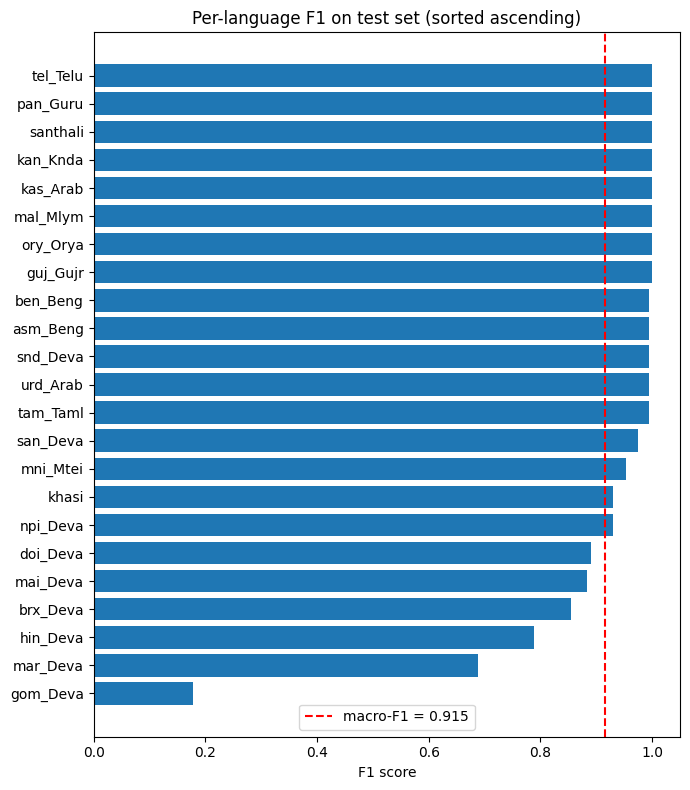

In [6]:
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(per_lang_df["language"], per_lang_df["f1"])
ax.axvline(test_report["macro_f1"], color="red", linestyle="--",
           label=f"macro-F1 = {test_report['macro_f1']:.3f}")
ax.set_xlabel("F1 score")
ax.set_title("Per-language F1 on test set (sorted ascending)")
ax.legend()
plt.tight_layout()
plt.savefig("../data/per_language_f1.png", dpi=110)
plt.show()


## Confusion matrix (test set) + biggest confusion pairs

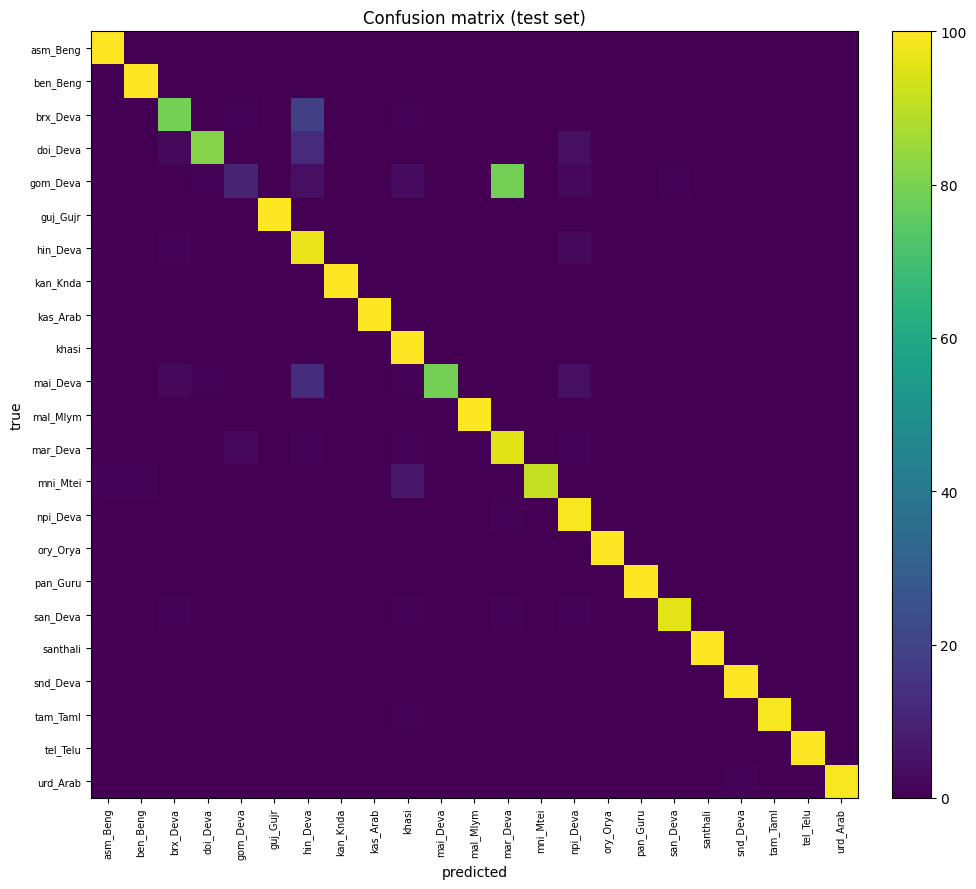

In [7]:
cm = test_report["confusion_matrix"]

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cm, cmap="viridis")
ax.set_xticks(range(len(LANGUAGES)))
ax.set_xticklabels(LANGUAGES, rotation=90, fontsize=7)
ax.set_yticks(range(len(LANGUAGES)))
ax.set_yticklabels(LANGUAGES, fontsize=7)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Confusion matrix (test set)")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("../data/confusion_matrix.png", dpi=110)
plt.show()


In [8]:
# Off-diagonal (true != predicted) pairs, sorted by how often they occur
pairs = []
for i in range(len(LANGUAGES)):
    for j in range(len(LANGUAGES)):
        if i != j and cm[i, j] > 0:
            pairs.append((cm[i, j], LANGUAGES[i], LANGUAGES[j]))
pairs.sort(reverse=True)

print(f"{'count':>5}  {'true':12}  predicted")
for count, true_lang, pred_lang in pairs[:15]:
    print(f"{count:5d}  {true_lang:12}  {pred_lang}")


count  true          predicted
   79  gom_Deva      mar_Deva
   19  brx_Deva      hin_Deva
   13  mai_Deva      hin_Deva
   12  doi_Deva      hin_Deva
    7  mni_Mtei      khasi
    4  mai_Deva      npi_Deva
    4  gom_Deva      hin_Deva
    4  doi_Deva      npi_Deva
    3  gom_Deva      khasi
    2  mar_Deva      gom_Deva
    2  mai_Deva      brx_Deva
    2  hin_Deva      npi_Deva
    2  gom_Deva      npi_Deva
    2  doi_Deva      brx_Deva
    1  urd_Arab      snd_Deva


## Final summary

In [9]:
summary = {
    "val_macro_f1": float(val_report["macro_f1"]),
    "test_macro_f1": float(test_report["macro_f1"]),
    "per_language_f1_test": {lang: float(f1) for lang, f1 in zip(LANGUAGES, test_report["f1"])},
}
with open(os.path.join(DATA_DIR, "final_results.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print(f"FINAL TEST MACRO-F1: {test_report['macro_f1']:.4f}")
print(f"Worst 3 languages: {per_lang_df.head(3)[['language','f1']].to_dict('records')}")
print(f"Best 3 languages:  {per_lang_df.tail(3)[['language','f1']].to_dict('records')}")


FINAL TEST MACRO-F1: 0.9150
Worst 3 languages: [{'language': 'gom_Deva', 'f1': 0.17699115044247787}, {'language': 'mar_Deva', 'f1': 0.6884057971014493}, {'language': 'hin_Deva', 'f1': 0.7886178861788617}]
Best 3 languages:  [{'language': 'santhali', 'f1': 1.0}, {'language': 'pan_Guru', 'f1': 1.0}, {'language': 'tel_Telu', 'f1': 1.0}]
